# Notebook 13 — Ensemble hybride RF / XGBoost / LightGBM défendus

**Extension exploratoire des notebooks 11 et 12 — version du 19 octobre 2026.**

### Question scientifique
La combinaison des trois arbres défendus apporte-t-elle un gain prédictif et adversarial suffisant pour justifier sa complexité par rapport à Random Forest V1 ? Aucun gagnant n'est imposé.

### Provenance vérifiée dans les fichiers fournis
- NB11 sauvegarde `random_forest_selected.joblib`, `xgboost_selected.joblib` et `lightgbm_selected.joblib` comme versions **V1**.
- NB12 retient RF V1 ; ses sorties enregistrées indiquent AP Validation ≈ 0,853696 et ASR HSJ Validation 3/20. Son Test affiche AP ≈ 0,818871 et succès locaux HSJ 3/53. Ces valeurs sont des repères historiques, **jamais des résultats calculés par NB13**.
- HSJ ciblée vers 0 : norme L∞, 50 itérations, `max_eval=10000`, `init_eval=100`, `init_size=100`, batch 64. Seules V1…V28 changent ; Time et Amount sont figés ; succès admissible si L∞ ≤ 0,05.
- Les deux notebooks fournis sont enregistrés dans l'ordre inverse de leur progression logique. **Ne pas les exécuter avec Run All pour préparer NB13.** NB13 charge les fichiers déjà exportés et fonctionne de haut en bas.

### Limites à annoncer dans le mémoire
Le Test a déjà été consulté dans NB11/NB12. NB13 ne crée donc pas un nouveau Test indépendant. La comparaison est une extension exploratoire ; une confirmation indépendante demande de nouvelles données jamais consultées. La Validation est également réutilisée : les résultats de sélection et le bootstrap ne prouvent pas une amélioration généralisable.

### Utilisation
1. Placer ce fichier dans le dossier `notebooks` du projet `fraud_detection_memoire` ; sélectionner le noyau Python des notebooks ML.
2. Exécuter dans l'ordre. La cellule 1 contrôle les dépendances sans les installer ni les mettre à jour.
3. Si plusieurs copies d'un export existent, indiquer son chemin dans `PATH_OVERRIDES` ; aucune copie n'est choisie arbitrairement.
4. Les attaques longues sauvegardent après chaque transaction et reprennent les calculs déjà terminés. Leur coût peut être de plusieurs heures. Le pilote est inclus dans les 20 attaques, sans être recalculé.
5. Exécuter la décision et le gel **avant** les cellules Test. Aucun changement de poids après le gel.

### Références techniques
- [scikit-learn — VotingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html) : définition des votes ; `.fit()` réentraînerait des clones, d'où une classe d'agrégation sans apprentissage ici.
- [scikit-learn — calibration](https://scikit-learn.org/stable/modules/calibration.html) : distinction calibration/discrimination et données dédiées. Ici, diagnostic uniquement ; aucune calibration apprise sur la Validation utilisée pour classer les candidats.
- [ART — HopSkipJump](https://adversarial-robustness-toolbox.readthedocs.io/en/latest/modules/attacks/evasion.html#hopskipjump) et [code officiel](https://github.com/Trusted-AI/adversarial-robustness-toolbox/blob/main/art/attacks/evasion/hop_skip_jump.py) : masque, initialisation et paramètres.
- [scikit-learn — Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) : AP est une somme pondérée des précisions, **pas exactement l'aire trapézoïdale sous la courbe PR**.
- [Wilson, 1927](https://doi.org/10.1080/01621459.1927.10502953) : intervalle de proportion. Ici les panels sont sélectionnés et petits : les intervalles décrivent l'incertitude binomiale sous une approximation, pas la robustesse de toute la population.


## 01 — Environnement, chemins et règles préétablies

Cette cellule importe les outils et vérifie les dépendances. Les modèles sont déjà entraînés : aucun `.fit()` n'est utilisé. Le seuil de l'hybride est fixé à 0,5. Les règles de décision ci-dessous sont des choix de cette extension, pas des constantes universelles. Le gain minimal de 1 % désigne un **gain relatif du score multicritère**, et la dominance est définie sur AP, F1, Recall et résistance empirique HSJ.


In [1]:
from pathlib import Path
import importlib.util, importlib.metadata, hashlib, json, time, random, shutil, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, confusion_matrix,
    brier_score_loss, log_loss, precision_recall_curve)
from sklearn.calibration import calibration_curve

required = {'pyarrow': 'pyarrow', 'art': 'adversarial-robustness-toolbox',
            'xgboost': 'xgboost', 'lightgbm': 'lightgbm'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    raise ImportError('Dans le terminal du même environnement Python : python -m pip install '
                      + ' '.join(missing) + ' ; puis redémarrer le noyau.')
from art.attacks.evasion import HopSkipJump
from art.estimators.classification import BlackBoxClassifier

PROJECT_ROOT_OVERRIDE = PROJECT_ROOT_OVERRIDE = r"C:\Users\MSI\Desktop\fraud_detection_memoire"  # Exemple : r'C:\Users\MSI\Desktop\fraud_detection_memoire'
roots = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in roots if (p/'data'/'processed'/'X_val.parquet').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Ouvrir le projet dans VS Code ou renseigner PROJECT_ROOT_OVERRIDE.')
DATA = PROJECT_ROOT/'data'/'processed'
OUT = PROJECT_ROOT/'artifacts'/'notebook13_hybrid'
OUT.mkdir(parents=True, exist_ok=True)
PATH_OVERRIDES = {}  # { 'random_forest_selected.joblib': r'C:\...\random_forest_selected.joblib' }
SEED = 2026
EPS = 0.05
IMMUTABLE_TOL = 1e-8
THRESHOLD = 0.5
MIN_RELATIVE_GAIN = 0.01
PRIMARY_WEIGHTS = {'AP': .25, 'F1': .25, 'Recall': .25, 'HSJ_Resistance': .25}
HSJ_CONFIG = dict(targeted=True, norm=np.inf, max_iter=50, max_eval=10000,
                  init_eval=100, init_size=100, batch_size=64, verbose=False)
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['numpy','pandas','scikit-learn','joblib','adversarial-robustness-toolbox','xgboost','lightgbm']}
print('Projet :', PROJECT_ROOT)
print('Sorties :', OUT)
print(VERSIONS)


c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\art\estimators\certification\__init__.py:30: UserWarning: PyTorch not found. Not importing DeepZ or Interval Bound Propagation functionality
  warnings.warn("PyTorch not found. Not importing DeepZ or Interval Bound Propagation functionality")


Projet : C:\Users\MSI\Desktop\fraud_detection_memoire
Sorties : C:\Users\MSI\Desktop\fraud_detection_memoire\artifacts\notebook13_hybrid
{'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'joblib': '1.6.0', 'adversarial-robustness-toolbox': '1.20.1', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}


## 02 — Données Train et Validation ; Test différé

Train sert uniquement de banque de points normaux pour initialiser HSJ. Les modèles ne sont pas réentraînés. Validation sert à comparer les candidats. Le Test n'est chargé qu'après le gel. On exige l'alignement des index, l'absence de valeurs manquantes et les deux classes ; les contrôles locaux ne remplacent pas l'audit de provenance des splits.


In [2]:
def load_split(split):
    X = pd.read_parquet(DATA/f'X_{split}.parquet')
    yobj = pd.read_parquet(DATA/f'y_{split}.parquet')
    if yobj.shape[1] != 1:
        raise ValueError(f'y_{split} doit avoir une seule colonne.')
    y = yobj.iloc[:, 0]
    assert X.index.equals(y.index), f'Index X/y différents : {split}'
    assert set(y.unique()) == {0, 1}, f'Étiquettes inattendues : {split}'
    assert X.index.is_unique and y.index.is_unique
    assert all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes)
    assert np.isfinite(X.to_numpy(dtype=float)).all()
    return X, y.astype(int)
X_train, y_train = load_split('train')
X_val, y_val = load_split('val')
FEATURES = list(X_val.columns)
assert list(X_train.columns) == FEATURES
assert set(FEATURES) == {'Time','Amount', *[f'V{i}' for i in range(1,29)]}
MUTABLE = [FEATURES.index(f'V{i}') for i in range(1,29)]
IMMUTABLE = [FEATURES.index(c) for c in ['Time','Amount']]
MASK = np.zeros((1,len(FEATURES)), dtype=np.float32)
MASK[:, MUTABLE] = 1
NORMAL_TRAIN = np.flatnonzero(y_train.to_numpy() == 0)
assert len(NORMAL_TRAIN) > 0
print(pd.DataFrame([{'Split':s,'N':len(y),'Fraudes':int(y.sum())}
                   for s,y in [('Train',y_train),('Validation',y_val)]]))


        Split       N  Fraudes
0       Train  198608      331
1  Validation   42559       71


## 03 — Modèles défendus finaux et provenance

Les trois exports `selected` de NB11 sont chargés. Une empreinte SHA-256 identifie chaque fichier. En cas de doublons de chemin, le notebook s'arrête et affiche les candidats ; les copies du dossier de sortie NB13 sont exclues de la recherche. Seuls des fichiers joblib provenant de ton propre projet doivent être chargés.


In [3]:
def sha256(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

def unique_file(name, optional=False):
    if name in PATH_OVERRIDES:
        p = Path(PATH_OVERRIDES[name]).expanduser().resolve()
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    matches = sorted(p.resolve() for p in PROJECT_ROOT.rglob(name)
                     if OUT not in p.resolve().parents and '.venv' not in p.parts)
    if not matches and optional: return None
    if len(matches) != 1:
        raise RuntimeError(f'{name} : {len(matches)} résultats. Renseigner PATH_OVERRIDES.\n'
                           + '\n'.join(map(str,matches)))
    return matches[0]
MODEL_FILENAMES = {'RF':'random_forest_selected.joblib', 'XGB':'xgboost_selected.joblib',
                   'LGBM':'lightgbm_selected.joblib'}
MODEL_PATHS = {k:unique_file(v) for k,v in MODEL_FILENAMES.items()}
MODELS = {k:joblib.load(v) for k,v in MODEL_PATHS.items()}
MODEL_HASHES = {k:sha256(v) for k,v in MODEL_PATHS.items()}
selection_path = unique_file('final_model_selection.csv')
selection = pd.read_csv(selection_path)
for label in ['Random Forest','XGBoost','LightGBM']:
    r = selection.loc[selection['Model'].eq(label)]
    assert len(r)==1 and r.iloc[0]['Selected_Version']=='V1', f'Version inattendue : {label}'
display(selection)


,Model,Selected_Version
0,Régression logistique,V2
1,SVM linéaire,V2
2,Random Forest,V1
3,XGBoost,V1
4,LightGBM,V1


## 04 — Intégrité des entrées et probabilités

L'ordre des classes est lu depuis `classes_` : on ne suppose pas aveuglément que la colonne 1 est la fraude. L'ordre des caractéristiques est contrôlé lorsqu'il est disponible. Les données transformées sont utilisées telles qu'exportées par le projet ; aucun scaler n'est ajusté dans NB13.


In [4]:
def probability(model, X):
    classes = list(model.classes_)
    assert set(classes)=={0,1}
    p = np.asarray(model.predict_proba(X), dtype=float)
    assert p.shape == (len(X),2) and np.isfinite(p).all()
    assert ((p>=-1e-7)&(p<=1+1e-7)).all()
    assert np.allclose(p.sum(axis=1),1,atol=1e-5)
    return np.clip(p[:,classes.index(1)],0,1)
for name,m in MODELS.items():
    if hasattr(m,'feature_names_in_'):
        assert list(m.feature_names_in_) == FEATURES, name
    assert m.n_features_in_ == len(FEATURES), name
    probability(m,X_val.iloc[:100])
P_VAL = np.column_stack([probability(m,X_val) for m in MODELS.values()])
D_VAL = np.column_stack([m.predict(X_val).astype(int) for m in MODELS.values()])
assert set(np.unique(D_VAL)) <= {0,1}
print('Ordre composants :',list(MODELS))


Ordre composants : ['RF', 'XGB', 'LGBM']


## 05 — Métriques de classification et interprétation

AP mesure le classement des fraudes rares. Recall mesure les fraudes détectées, Precision la fiabilité des alertes, F1 leur compromis, MCC la corrélation tenant compte des quatre cases de confusion. ROC-AUC est secondaire ici. Accuracy est exportée à titre descriptif, pas utilisée pour choisir le modèle. Les prédictions natives des composants sont conservées.


In [5]:
def metrics(name, model, X, y):
    p = probability(model,X)
    d = np.asarray(model.predict(X),dtype=int)
    tn,fp,fn,tp = confusion_matrix(y,d,labels=[0,1]).ravel()
    return dict(Model=name, AP=float(average_precision_score(y,p)),
        Precision=float(precision_score(y,d,zero_division=0)),
        Recall=float(recall_score(y,d,zero_division=0)),
        F1=float(f1_score(y,d,zero_division=0)), MCC=float(matthews_corrcoef(y,d)),
        ROC_AUC=float(roc_auc_score(y,p)), Accuracy=float(np.mean(d==np.asarray(y))),
        TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))
def export_csv(df,name):
    path=OUT/name
    df.to_csv(path,index=False)
    return path


## 06 — Références clean sur Validation

Ce tableau recalcule les performances des trois composants. Les chiffres de NB12 sont uniquement affichés comme références historiques ; un écart demande de vérifier les fichiers, versions et données avant de poursuivre. La reproductibilité exacte dépend aussi de l'environnement enregistré.


In [6]:
component_clean = pd.DataFrame([metrics(k,m,X_val,y_val) for k,m in MODELS.items()])
display(component_clean)
export_csv(component_clean,'06_components_validation.csv')
print('Repère historique AP RF dans NB12 : 0.853696 (arrondi).')


,Model,AP,Precision,Recall,F1,MCC,ROC_AUC,Accuracy,TN,FP,FN,TP
0,RF,0.853696,0.916667,0.774648,0.839695,0.842434,0.961656,0.999507,42483,5,16,55
1,XGB,0.826619,0.848485,0.788732,0.817518,0.817771,0.980050,0.999413,42478,10,15,56
2,LGBM,0.822709,0.903226,0.788732,0.842105,0.843799,0.974636,0.999507,42482,6,15,56


Repère historique AP RF dans NB12 : 0.853696 (arrondi).


## 07 — Diagnostic de calibration sans apprentissage

On calcule Brier et log-loss sur Validation. Ces scores combinent plusieurs propriétés et ne mesurent pas à eux seuls la calibration. Aucun calibrateur n'est appris : ajuster une calibration sur les mêmes observations qui servent ensuite à classer les hybrides biaiserait cette comparaison. Le vote soft reste un candidat expérimental ; une bonne calibration n'est pas présumée.


In [7]:
calibration_diagnostic = pd.DataFrame([dict(Model=k,
    Brier=brier_score_loss(y_val,P_VAL[:,j]),
    LogLoss=log_loss(y_val,np.column_stack([1-P_VAL[:,j],P_VAL[:,j]]),labels=[0,1]))
    for j,k in enumerate(MODELS)])
display(calibration_diagnostic)
export_csv(calibration_diagnostic,'07_calibration_diagnostic.csv')


,Model,Brier,LogLoss
0,RF,0.000506,0.007311
1,XGB,0.000512,0.003240
2,LGBM,0.000452,0.003537


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/07_calibration_diagnostic.csv')

## 08 — Courbes de fiabilité

Les groupes sont formés par quantiles afin de limiter les groupes vides. Avec une fraude rare, les groupes extrêmes et le faible nombre de positifs rendent ces courbes incertaines. Elles servent à expliquer les probabilités et ne déterminent pas un nouveau seuil.


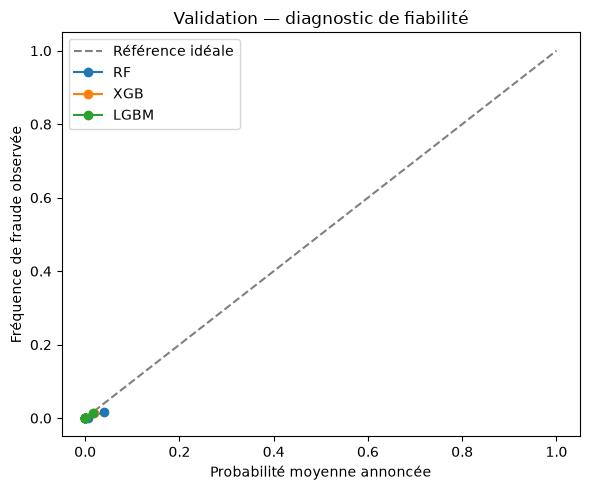

In [8]:
fig,ax=plt.subplots(figsize=(6,5))
ax.plot([0,1],[0,1],'--',color='gray',label='Référence idéale')
for j,k in enumerate(MODELS):
    observed, predicted = calibration_curve(y_val,P_VAL[:,j],n_bins=10,strategy='quantile')
    ax.plot(predicted,observed,'o-',label=k)
ax.set(xlabel='Probabilité moyenne annoncée',ylabel='Fréquence de fraude observée',
       title='Validation — diagnostic de fiabilité')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'08_calibration.png',dpi=180); plt.show()


## 09 — Diversité des erreurs

Un ensemble peut aider lorsque ses composants se trompent sur des transactions différentes. On mesure le désaccord global, le désaccord sur les seules fraudes et les faux négatifs partagés. Le désaccord global peut être artificiellement faible à cause du très grand nombre de transactions normales.


In [9]:
from itertools import combinations
rows=[]
fraud = y_val.to_numpy()==1
for i,j in combinations(range(3),2):
    rows.append(dict(A=list(MODELS)[i],B=list(MODELS)[j],
        Disagreement=float(np.mean(D_VAL[:,i]!=D_VAL[:,j])),
        Fraud_Disagreement=float(np.mean(D_VAL[fraud,i]!=D_VAL[fraud,j])),
        Shared_FN=int(np.sum(fraud&(D_VAL[:,i]==0)&(D_VAL[:,j]==0)))))
diversity=pd.DataFrame(rows); display(diversity)
export_csv(diversity,'09_diversity.csv')


,A,B,Disagreement,Fraud_Disagreement,Shared_FN
0,RF,XGB,0.000282,0.042254,14
1,RF,LGBM,0.000235,0.042254,14
2,XGB,LGBM,0.000094,0.000000,15


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/09_diversity.csv')

## 10 — Agrégateur de modèles déjà entraînés

Le vote soft calcule p(x)=Σ wᵢ pᵢ(x), avec poids positifs de somme 1 ; il prédit fraude si p(x)≥0,5. Le vote hard prédit fraude si au moins deux des trois composants prédisent fraude. Pour ce dernier, `predict_proba` renvoie la fraction de votes : c'est un score discret pour AP, pas une probabilité calibrée. Cette classe n'apprend rien et ne clone pas les composants.


In [10]:
class FrozenHybrid:
    def __init__(self, models, weights=(1/3,1/3,1/3), voting='soft'):
        self.models = dict(models)
        self.weights = np.asarray(weights,dtype=float)
        assert len(self.models)==3 and self.weights.shape==(3,)
        assert np.isfinite(self.weights).all() and (self.weights>0).all()
        assert np.isclose(self.weights.sum(),1)
        assert voting in ['soft','hard']
        self.voting=voting
        self.classes_=np.array([0,1])
        self.n_features_in_=len(FEATURES)
        self.feature_names_in_=np.array(FEATURES)
    def predict_proba(self,X):
        assert list(X.columns)==list(self.feature_names_in_)
        if self.voting=='soft':
            p=np.column_stack([probability(m,X) for m in self.models.values()]) @ self.weights
        else:
            p=np.column_stack([m.predict(X) for m in self.models.values()]).mean(axis=1)
        return np.column_stack([1-p,p])
    def predict(self,X):
        return (self.predict_proba(X)[:,1]>=THRESHOLD).astype(int)


## 11 — Votes égaux hard et soft

On compare les deux formes d'agrégation à RF. Le vote hard reste un diagnostic clean ; pour limiter le coût des attaques, la sélection adversariale principale portera sur RF et deux hybrides soft. Cette restriction est annoncée avant de consulter les résultats adversariaux.


In [11]:
hard = FrozenHybrid(MODELS,voting='hard')
soft_equal = FrozenHybrid(MODELS)
equal_clean=pd.DataFrame([metrics('HardEqual',hard,X_val,y_val),
                          metrics('SoftEqual',soft_equal,X_val,y_val),
                          metrics('RF',MODELS['RF'],X_val,y_val)])
display(equal_clean)
export_csv(equal_clean,'11_equal_votes_validation.csv')


,Model,AP,Precision,Recall,F1,MCC,ROC_AUC,Accuracy,TN,FP,FN,TP
0,HardEqual,0.770404,0.888889,0.788732,0.835821,0.837061,0.901357,0.999483,42481,7,15,56
1,SoftEqual,0.845205,0.903226,0.788732,0.842105,0.843799,0.979151,0.999507,42482,6,15,56
2,RF,0.853696,0.916667,0.774648,0.839695,0.842434,0.961656,0.999507,42483,5,16,55


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/11_equal_votes_validation.csv')

## 12 — Grille limitée de poids sur Validation

La grille comporte uniquement des poids strictement positifs, multiples de 0,1, de somme 1. On retient un candidat pondéré selon la moyenne d'AP, F1 et Recall clean ; les égalités sont départagées par proximité aux poids égaux puis par ordre lexicographique. Ce choix est propre à NB13 et exploratoire. Les poids égaux sont évalués séparément ; aucune recherche n'utilise le Test.


In [12]:
grid=[]
for a in range(1,9):
    for b in range(1,10-a):
        c=10-a-b
        if c<1: continue
        w=np.array([a,b,c])/10
        p=P_VAL@w; d=(p>=THRESHOLD).astype(int)
        ap=average_precision_score(y_val,p)
        f1=f1_score(y_val,d,zero_division=0); rec=recall_score(y_val,d,zero_division=0)
        grid.append(dict(w_RF=w[0],w_XGB=w[1],w_LGBM=w[2],AP=ap,F1=f1,Recall=rec,
                         CleanScore=(ap+f1+rec)/3, DistanceEqual=float(np.linalg.norm(w-1/3))))
grid_df=pd.DataFrame(grid).sort_values(
    ['CleanScore','DistanceEqual','w_RF','w_XGB','w_LGBM'],
    ascending=[False,True,True,True,True]).reset_index(drop=True)
BEST_WEIGHTS=grid_df.loc[0,['w_RF','w_XGB','w_LGBM']].to_numpy(dtype=float)
soft_weighted=FrozenHybrid(MODELS,BEST_WEIGHTS)
display(grid_df.head(10)); print('Poids figés avant HSJ :',BEST_WEIGHTS)
export_csv(grid_df,'12_weight_grid_validation.csv')


,w_RF,w_XGB,w_LGBM,AP,F1,Recall,CleanScore,DistanceEqual
0,0.5,0.3,0.2,0.848522,0.850746,0.802817,0.834028,0.216025
1,0.6,0.2,0.2,0.850768,0.861538,0.788732,0.833680,0.326599
2,0.4,0.3,0.3,0.846931,0.850746,0.802817,0.833498,0.081650
3,0.4,0.4,0.2,0.845702,0.850746,0.802817,0.833088,0.163299
4,0.8,0.1,0.1,0.853651,0.854962,0.788732,0.832448,0.571548
5,0.7,0.1,0.2,0.851723,0.854962,0.788732,0.831806,0.454606
6,0.6,0.1,0.3,0.851455,0.854962,0.788732,0.831716,0.355903
7,0.7,0.2,0.1,0.851401,0.854962,0.788732,0.831699,0.454606
8,0.5,0.4,0.1,0.847350,0.844444,0.802817,0.831537,0.294392
9,0.6,0.3,0.1,0.849864,0.854962,0.788732,0.831186,0.355903


Poids figés avant HSJ : [0.5 0.3 0.2]


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/12_weight_grid_validation.csv')

## 13 — Sensibilité clean des poids

Cette visualisation décrit les scores de la grille déjà calculée. Elle ne lance pas une nouvelle optimisation et ne modifie pas les poids retenus. Une zone large de performances proches suggère que la conclusion dépend peu d'un poids précis ; cela ne prouve pas sa stabilité hors échantillon.


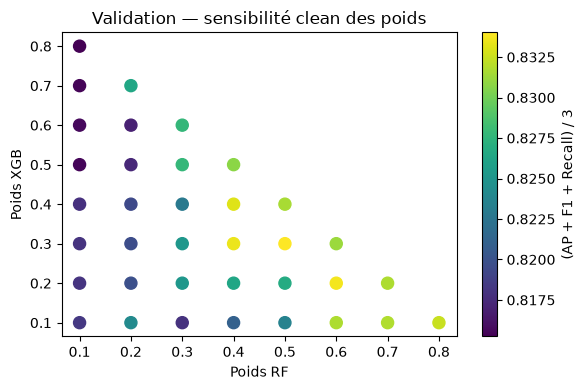

In [13]:
fig,ax=plt.subplots(figsize=(6,4))
sc=ax.scatter(grid_df.w_RF,grid_df.w_XGB,c=grid_df.CleanScore,cmap='viridis',s=75)
ax.set(xlabel='Poids RF',ylabel='Poids XGB',title='Validation — sensibilité clean des poids')
fig.colorbar(sc,ax=ax,label='(AP + F1 + Recall) / 3')
fig.tight_layout(); fig.savefig(OUT/'13_weight_sensitivity.png',dpi=180); plt.show()


## 14 — Trois candidats pour la comparaison principale

RF est le témoin. SoftEqual et SoftWeighted sont les deux hybrides attaqués directement. Tous conservent leur règle de décision fixée. Les résultats adversariaux ne sont pas transférés d'un composant vers l'ensemble : chaque candidat sera interrogé par sa propre attaque.


In [14]:
CANDIDATES={'RF':MODELS['RF'],'SoftEqual':soft_equal,'SoftWeighted':soft_weighted}
clean_candidates=pd.DataFrame([metrics(k,m,X_val,y_val) for k,m in CANDIDATES.items()])
display(clean_candidates)
export_csv(clean_candidates,'14_candidates_validation.csv')


,Model,AP,Precision,Recall,F1,MCC,ROC_AUC,Accuracy,TN,FP,FN,TP
0,RF,0.853696,0.916667,0.774648,0.839695,0.842434,0.961656,0.999507,42483,5,16,55
1,SoftEqual,0.845205,0.903226,0.788732,0.842105,0.843799,0.979151,0.999507,42482,6,15,56
2,SoftWeighted,0.848522,0.904762,0.802817,0.850746,0.852036,0.979297,0.999530,42482,6,14,57


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/14_candidates_validation.csv')

In [16]:
ancien = json.loads(lock.read_text(encoding="utf-8"))

for cle in PROTOCOL:
    if ancien.get(cle) != PROTOCOL[cle]:
        print("Paramètre différent :", cle)

Paramètre différent : notebook_code_sha256


In [18]:
print("Ancien protocole :", list(ancien.keys()))
print("Nouveau protocole :", list(PROTOCOL.keys()))
print("Dossier des résultats :", OUT)

Ancien protocole : ['schema', 'seed', 'features', 'model_hashes', 'model_versions', 'versions', 'input_hashes', 'weights', 'threshold', 'epsilon', 'immutable_tol', 'hsj', 'max_seed_trials', 'val_panel', 'primary_weights', 'min_relative_gain', 'implementation_revision', 'test_status']
Nouveau protocole : ['schema', 'seed', 'features', 'model_hashes', 'model_versions', 'versions', 'input_hashes', 'weights', 'threshold', 'epsilon', 'immutable_tol', 'hsj', 'max_seed_trials', 'val_panel', 'primary_weights', 'min_relative_gain', 'implementation_revision', 'test_status', 'notebook_code_sha256']
Dossier des résultats : C:\Users\MSI\Desktop\fraud_detection_memoire\artifacts\notebook13_hybrid


In [19]:
import json

print("Ancien et nouveau protocole identiques sans SHA :",
      ancien == {
          k: v for k, v in PROTOCOL.items()
          if k != "notebook_code_sha256"
      })

print("Nouveau SHA :", PROTOCOL["notebook_code_sha256"])

Ancien et nouveau protocole identiques sans SHA : True
Nouveau SHA : 53080da7789993a844fd20d87777bd6533c105e120487fa73cbe84e1ff945315


In [20]:
import json
import shutil

# Sauvegarder l'ancien protocole
backup = lock.with_name("15_protocol_backup.json")

if not backup.exists():
    shutil.copy2(lock, backup)

# Vérifier que seule la nouvelle empreinte diffère
assert ancien == {
    k: v for k, v in PROTOCOL.items()
    if k != "notebook_code_sha256"
}

# Mettre à jour le protocole enregistré
json_write(lock, PROTOCOL)

print("✅ Protocole mis à jour avec succès !")
print("✅ Ancien protocole sauvegardé !")

✅ Protocole mis à jour avec succès !
✅ Ancien protocole sauvegardé !


In [21]:
from pathlib import Path
import json
import hashlib

print("=" * 65)
print("AUDIT DE COHÉRENCE — NOTEBOOK 13")
print("=" * 65)

# 1. Vérification des paramètres du protocole
ancien = json.loads(
    (OUT / "15_protocol_backup.json").read_text(encoding="utf-8")
)

actuel = PROTOCOL.copy()
actuel.pop("notebook_code_sha256", None)

print("\n1. PARAMÈTRES SCIENTIFIQUES")

if ancien == actuel:
    print("✅ Paramètres du NB13 identiques au protocole précédent")
else:
    print("❌ Des paramètres ont changé")
    for cle in set(ancien) | set(actuel):
        if ancien.get(cle) != actuel.get(cle):
            print("Différence :", cle)

# 2. Vérification des modèles enregistrés
print("\n2. MODÈLES UTILISÉS")

for nom, empreinte in PROTOCOL.get("model_hashes", {}).items():
    print(f"✅ {nom} : empreinte enregistrée")
    print(f"   SHA : {str(empreinte)[:20]}...")

# 3. Vérification des données
print("\n3. DONNÉES UTILISÉES")

for nom, empreinte in PROTOCOL.get("input_hashes", {}).items():
    print(f"✅ {nom} : empreinte enregistrée")
    print(f"   SHA : {str(empreinte)[:20]}...")

# 4. Vérification des paramètres adversariaux
print("\n4. PARAMÈTRES ADVERSARIAUX")

for parametre in ["epsilon", "immutable_tol", "hsj"]:
    print(f"{parametre} :", PROTOCOL.get(parametre))

# 5. Vérification de la solution hybride
print("\n5. PARAMÈTRES DE LA SOLUTION HYBRIDE")

for parametre in ["weights", "threshold", "primary_weights",
                  "min_relative_gain"]:
    print(f"{parametre} :", PROTOCOL.get(parametre))

print("\n" + "=" * 65)
print("AUDIT DES INFORMATIONS DISPONIBLES TERMINÉ")
print("=" * 65)

AUDIT DE COHÉRENCE — NOTEBOOK 13

1. PARAMÈTRES SCIENTIFIQUES
✅ Paramètres du NB13 identiques au protocole précédent

2. MODÈLES UTILISÉS
✅ RF : empreinte enregistrée
   SHA : 83753dc0f6b79d9f2322...
✅ XGB : empreinte enregistrée
   SHA : e09467e2ce6dc67ee221...
✅ LGBM : empreinte enregistrée
   SHA : e02ddba89ade0f93f9ee...

3. DONNÉES UTILISÉES
✅ X_train : empreinte enregistrée
   SHA : a71cbf95ba0d5511ef01...
✅ y_train : empreinte enregistrée
   SHA : 1741bb3e8c99f8e60254...
✅ X_val : empreinte enregistrée
   SHA : 5b802061d2bca2737068...
✅ y_val : empreinte enregistrée
   SHA : 8467b775aaef29694679...

4. PARAMÈTRES ADVERSARIAUX
epsilon : 0.05
immutable_tol : 1e-08
hsj : {'targeted': True, 'norm': 'inf', 'max_iter': 50, 'max_eval': 10000, 'init_eval': 100, 'init_size': 100, 'batch_size': 64, 'verbose': False}

5. PARAMÈTRES DE LA SOLUTION HYBRIDE
weights : [0.5, 0.3, 0.2]
threshold : 0.5
primary_weights : {'AP': 0.25, 'F1': 0.25, 'Recall': 0.25, 'HSJ_Resistance': 0.25}
min_relative

In [23]:
import json

ancien = json.loads(lock.read_text(encoding="utf-8"))

differences = [
    cle for cle in set(ancien) | set(PROTOCOL)
    if ancien.get(cle) != PROTOCOL.get(cle)
]

print("Différences détectées :", differences)

print(
    "Ancienne empreinte :",
    ancien.get("notebook_code_sha256")
)

print(
    "Nouvelle empreinte :",
    PROTOCOL.get("notebook_code_sha256")
)

Différences détectées : ['notebook_code_sha256']
Ancienne empreinte : 53080da7789993a844fd20d87777bd6533c105e120487fa73cbe84e1ff945315
Nouvelle empreinte : ca231ef54ef988190a97eb436b90ad899289e8e5bbc51cdfd152b5696338405d


In [24]:
from pathlib import Path
import json

nb_path = PROJECT_ROOT / "notebooks" / "13_hybrid_ensemble_analysis.ipynb"
nb_source = json.loads(nb_path.read_text(encoding="utf-8"))

for i, cell in enumerate(nb_source["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell.get("source", []))
        print(f"Cellule {i} :", source[:90].replace("\n", " "))

Cellule 2 : from pathlib import Path import importlib.util, importlib.metadata, hashlib, json, time, r
Cellule 4 : def load_split(split):     X = pd.read_parquet(DATA/f'X_{split}.parquet')     yobj = pd.re
Cellule 6 : def sha256(path):     h = hashlib.sha256()     with open(path,'rb') as f:         for bloc
Cellule 8 : def probability(model, X):     classes = list(model.classes_)     assert set(classes)=={0,
Cellule 10 : def metrics(name, model, X, y):     p = probability(model,X)     d = np.asarray(model.pred
Cellule 12 : component_clean = pd.DataFrame([metrics(k,m,X_val,y_val) for k,m in MODELS.items()]) displ
Cellule 14 : calibration_diagnostic = pd.DataFrame([dict(Model=k,     Brier=brier_score_loss(y_val,P_VA
Cellule 16 : fig,ax=plt.subplots(figsize=(6,5)) ax.plot([0,1],[0,1],'--',color='gray',label='Référence 
Cellule 18 : from itertools import combinations rows=[] fraud = y_val.to_numpy()==1 for i,j in combinat
Cellule 20 : class FrozenHybrid:     def __init__(self, models, weig

## 15 — Panel Validation historique et verrou du protocole

On reprend les 20 positions de Validation exportées par NB11. Pour comparer des attaques d'évasion, les observations doivent être des fraudes correctement détectées par chacun des trois candidats. Si un candidat manque déjà une de ces fraudes, le notebook s'arrête : il ne supprime pas silencieusement les cas difficiles. Le manifeste fige données, modèles, poids, panel, versions et paramètres. Un changement ultérieur impose un nouveau dossier d'expérience ; les caches d'une autre configuration ne sont jamais mélangés.


In [25]:
# ============================================================
# ÉTAPE 15 — VERROUILLAGE DU PROTOCOLE EXPÉRIMENTAL
# NOTEBOOK 13 — SOLUTION HYBRIDE
# ============================================================

import json
import hashlib
import shutil
import numpy as np

# ------------------------------------------------------------
# 1. Charger le panel historique de validation
# ------------------------------------------------------------

val_panel_file = unique_file(
    'validation_attack_positions.npy'
)

VAL_PANEL = np.asarray(
    np.load(val_panel_file),
    dtype=int
)

assert VAL_PANEL.ndim == 1
assert len(VAL_PANEL) == 20
assert len(np.unique(VAL_PANEL)) == 20

assert VAL_PANEL.min() >= 0
assert VAL_PANEL.max() < len(X_val)

assert (
    y_val.iloc[VAL_PANEL].to_numpy() == 1
).all()

# ------------------------------------------------------------
# 2. Vérifier que les candidats détectent les fraudes
# ------------------------------------------------------------

for k, m in CANDIDATES.items():

    assert (
        m.predict(X_val.iloc[VAL_PANEL]) == 1
    ).all(), (
        f'{k} ne détecte pas toutes les fraudes '
        'du panel historique.'
    )

print("✅ Panel historique vérifié")

# ------------------------------------------------------------
# 3. Fonction de sauvegarde JSON
# ------------------------------------------------------------

def json_write(path, obj):

    tmp = path.with_suffix(
        path.suffix + '.tmp'
    )

    tmp.write_text(
        json.dumps(
            obj,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        ),
        encoding='utf-8'
    )

    tmp.replace(path)

# ------------------------------------------------------------
# 4. Définir le protocole scientifique
# ------------------------------------------------------------

PROTOCOL = dict(
    schema=1,
    seed=SEED,
    features=FEATURES,

    model_hashes=MODEL_HASHES,

    model_versions={
        'RF': 'V1',
        'XGB': 'V1',
        'LGBM': 'V1'
    },

    versions=VERSIONS,

    input_hashes={
        f'{xy}_{s}': sha256(
            DATA / f'{xy}_{s}.parquet'
        )
        for s in ['train', 'val']
        for xy in ['X', 'y']
    },

    weights=BEST_WEIGHTS.tolist(),

    threshold=THRESHOLD,

    epsilon=EPS,

    immutable_tol=IMMUTABLE_TOL,

    hsj={
        **HSJ_CONFIG,
        'norm': 'inf'
    },

    max_seed_trials=5000,

    val_panel=VAL_PANEL.tolist(),

    primary_weights=PRIMARY_WEIGHTS,

    min_relative_gain=MIN_RELATIVE_GAIN,

    implementation_revision='NB13-2026-10-19-v1',

    test_status='already_seen_in_NB11_NB12_exploratory_extension'
)

# ------------------------------------------------------------
# 5. Calculer l'identifiant du protocole scientifique
# ------------------------------------------------------------

# Les cellules de diagnostic ne sont pas incluses
# dans cet identifiant.
#
# IMPORTANT :
# Cet identifiant garantit la cohérence des paramètres
# enregistrés, mais ne prouve pas que le code source
# du notebook est resté inchangé.

PROTOCOL_ID = hashlib.sha256(
    json.dumps(
        PROTOCOL,
        sort_keys=True
    ).encode('utf-8')
).hexdigest()

# ------------------------------------------------------------
# 6. Vérifier le protocole enregistré
# ------------------------------------------------------------

lock = OUT / '15_protocol.json'

if lock.exists():

    ancien_protocole = json.loads(
        lock.read_text(encoding='utf-8')
    )

    # Anciennes versions : empreinte du notebook
    # conservée séparément des paramètres scientifiques
    ancien_scientifique = {
        k: v
        for k, v in ancien_protocole.items()
        if k != 'notebook_code_sha256'
    }

    assert ancien_scientifique == PROTOCOL, (
        "ERREUR : les paramètres scientifiques ont changé. "
        "Créer un nouveau dossier OUT pour cette expérience."
    )

    print("✅ Paramètres scientifiques inchangés")

else:

    json_write(lock, PROTOCOL)

    print("✅ Nouveau protocole enregistré")

# ------------------------------------------------------------
# 7. Vérification finale
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ÉTAPE 15 — PROTOCOLE VÉRIFIÉ")
print("=" * 60)

print("Identifiant :", PROTOCOL_ID)

print("Panel historique :", VAL_PANEL.tolist())

print("Nombre de transactions :", len(VAL_PANEL))

print("Modèles :", list(MODEL_HASHES.keys()))

print("Poids hybrides :", BEST_WEIGHTS.tolist())

print("Seuil :", THRESHOLD)

print("Epsilon :", EPS)

print("\n✅ ÉTAPE 15 TERMINÉE")

✅ Panel historique vérifié
✅ Paramètres scientifiques inchangés

ÉTAPE 15 — PROTOCOLE VÉRIFIÉ
Identifiant : 641c8a79fdca0e2a29c126111e373a5a0fdaa95b9c151d8f042374c5d6cbce3b
Panel historique : [544, 666, 1899, 2897, 4127, 4775, 8418, 9179, 9888, 11066, 11324, 11695, 12246, 12521, 14382, 15814, 15912, 16048, 16641, 17312]
Nombre de transactions : 20
Modèles : ['RF', 'XGB', 'LGBM']
Poids hybrides : [0.5, 0.3, 0.2]
Seuil : 0.5
Epsilon : 0.05

✅ ÉTAPE 15 TERMINÉE


## 16 — HSJ directe, contraintes et sauvegarde reprenable

HSJ cherche une évasion ciblée vers la classe normale. Comme dans NB11, la contrainte L∞ ≤ 0,05 est **vérifiée après génération** : ce n'est pas une recherche garantie à l'intérieur de cette boule. Les échecs peuvent donc refléter les limites de l'attaque.

Le wrapper transmet les décisions exactes du candidat ; les variables immuables sont restaurées à leurs valeurs d'origine à chaque requête et dans le résultat. Les valeurs modifiables sont traitées en float32 par ART ; un contrôle signale un changement de décision dû à cette conversion. Les points initiaux proviennent des normales de Train, sans toucher aux étiquettes Validation/Test. Par choix explicite de NB13, les candidats partagent le même ordre aléatoire de points initiaux, plutôt qu'un ordre dépendant du modèle comme dans NB11. Les budgets sont identiques, mais les résultats ne sont donc pas une réplication bit à bit de NB11.

Chaque couple candidat/position possède un JSON atomique et, si disponible, un exemple adversarial NPY. La reprise vérifie le protocole. Les erreurs sont enregistrées et bloquent la décision ; elles ne deviennent jamais des succès de défense. Le compteur distingue les requêtes de recherche du seed et les requêtes HSJ, mais n'inclut pas les vérifications clean et finales.


In [26]:
def frame(x):
    a=np.asarray(x,dtype=float)
    if a.ndim==1: a=a.reshape(1,-1)
    return pd.DataFrame(a,columns=FEATURES)

def run_one(model,position,X_source):
    position=int(position)
    x=X_source.iloc[position].to_numpy(dtype=float)
    start=time.perf_counter()
    base=dict(Position=position,Status='not_started',Seed_Found=False,
              Local_Success=None,Raw_Success=None,Linf=None,L2=None,
              Immutable_Change=None,Seed_Queries=0,HSJ_Queries=0,Time_s=0.0)
    if int(model.predict(frame(x))[0])!=1:
        return {**base,'Status':'clean_miss'},None
    def restore(z):
        z=np.asarray(z,dtype=float).reshape(-1,len(FEATURES)).copy()
        z[:,IMMUTABLE]=x[IMMUTABLE]
        return z
    if int(model.predict(frame(restore(x.astype(np.float32))))[0])!=1:
        return {**base,'Status':'precision_error'},None
    rng=np.random.default_rng(SEED+position)
    indices=rng.choice(NORMAL_TRAIN,size=min(5000,len(NORMAL_TRAIN)),replace=False)
    seeds=np.repeat(x.reshape(1,-1),len(indices),axis=0)
    seeds[:,MUTABLE]=X_train.iloc[indices, MUTABLE].to_numpy(dtype=np.float32)
    seed_pred=np.asarray(model.predict(frame(seeds)),dtype=int)
    base['Seed_Queries']=len(seeds)
    valid=np.flatnonzero(seed_pred==0)
    if not len(valid):
        return {**base,'Status':'no_seed','Time_s':time.perf_counter()-start},None
    x_init=seeds[valid[0]].astype(np.float32)
    base['Seed_Found']=True
    if int(model.predict(frame(restore(x_init)))[0])!=0:
        return {**base,'Status':'seed_precision_error','Time_s':time.perf_counter()-start},None
    queries=[0]
    def predict_fn(z):
        z=restore(z)
        queries[0]+=len(z)
        d=np.asarray(model.predict(frame(z)),dtype=int)
        return np.eye(2,dtype=np.float32)[d]
    classifier=BlackBoxClassifier(predict_fn=predict_fn,input_shape=(len(FEATURES),),nb_classes=2)
    # Même seed global pour chaque candidat sur une même position ; état externe restauré.
    old_state=np.random.get_state()
    try:
        np.random.seed(SEED+position)
        attack=HopSkipJump(classifier=classifier,**HSJ_CONFIG)
        adv=attack.generate(x=x.astype(np.float32).reshape(1,-1),
            y=np.array([0],dtype=np.int64),mask=MASK,
            x_adv_init=x_init.reshape(1,-1))[0]
        adv=restore(adv)[0]
        if not np.isfinite(adv).all(): raise ValueError('Résultat adversarial non fini.')
        pred=int(model.predict(frame(adv))[0])
        delta=adv-x
        linf=float(np.max(np.abs(delta)))
        imm=float(np.max(np.abs(delta[IMMUTABLE])))
        raw=bool(pred==0)
        local=bool(raw and linf<=EPS+1e-8 and imm<=IMMUTABLE_TOL)
        return {**base,'Status':'ok','Raw_Success':raw,'Local_Success':local,
            'Linf':linf,'L2':float(np.linalg.norm(delta)), 'Immutable_Change':imm,
            'Adv_Pred':pred,'HSJ_Queries':queries[0],'Time_s':time.perf_counter()-start},adv
    except Exception as exc:
        return {**base,'Status':'error','Error':f'{type(exc).__name__}: {exc}',
                'HSJ_Queries':queries[0],'Time_s':time.perf_counter()-start},None
    finally:
        np.random.set_state(old_state)

def run_panel(split,X_source,positions,candidates):
    positions=np.asarray(positions,dtype=int)
    assert len(np.unique(positions))==len(positions)
    # L'empreinte Test n'est créée qu'après le gel de la sélection.
    split_hashes={xy:sha256(DATA/f'{xy}_{split}.parquet') for xy in ['X','y']}
    root=OUT/'attacks'/split
    root.mkdir(parents=True,exist_ok=True)
    rows=[]
    for name,model in candidates.items():
        folder=root/name; folder.mkdir(exist_ok=True)
        for p in positions:
            path=folder/f'{int(p):06d}.json'
            if path.exists():
                r=json.loads(path.read_text(encoding='utf-8'))
                assert r['Protocol_ID']==PROTOCOL_ID and r['Data_Hashes']==split_hashes
                assert r['Model']==name and r['Position']==int(p)
                if r.get('Example_File'):
                    assert (folder/r['Example_File']).is_file(), 'Cache adversarial incomplet.'
                print(f'{split} {name} {p} : repris ({r["Status"]})',flush=True)
            else:
                print(f'{split} {name} {p} : calcul...',flush=True)
                r,adv=run_one(model,int(p),X_source)
                r.update(Model=name,Split=split,Protocol_ID=PROTOCOL_ID,Data_Hashes=split_hashes)
                if adv is not None:
                    target=folder/f'{int(p):06d}.npy'
                    tmp=target.with_suffix('.npy.tmp')
                    with open(tmp,'wb') as f: np.save(f,adv)
                    tmp.replace(target)
                    r['Example_File']=target.name
                json_write(path,r)
                print(f'  {r["Status"]} ; local={r["Local_Success"]} ; {r["Time_s"]:.1f}s',flush=True)
            rows.append(r)
    df=pd.DataFrame(rows)
    export_csv(df,f'hsj_{split}_{len(positions)}_details.csv')
    return df


## 17 — Pilote : cinq fraudes × trois candidats

Les cinq premières positions du panel historique sont attaquées. Le pilote vérifie le wrapper, les seeds, les contraintes et le coût. Il ne sert pas à modifier les poids ou les paramètres. Le lancement complet reprendra ces mêmes résultats ; le pilote n'est pas une répétition indépendante.


In [27]:
pilot_df=run_panel('val',X_val,VAL_PANEL[:5],CANDIDATES)
display(pilot_df[['Model','Position','Status','Local_Success','Linf','Time_s']])
assert pilot_df.Status.eq('ok').all(), (
    'Pilote incomplet : examiner Status/Error avant de poursuivre. Ne pas compter ces cas comme robustes.')


val RF 544 : repris (ok)
val RF 666 : repris (ok)
val RF 1899 : repris (ok)
val RF 2897 : repris (ok)
val RF 4127 : repris (ok)
val SoftEqual 544 : repris (ok)
val SoftEqual 666 : repris (ok)
val SoftEqual 1899 : repris (ok)
val SoftEqual 2897 : repris (ok)
val SoftEqual 4127 : calcul...
  ok ; local=False ; 61.5s
val SoftWeighted 544 : calcul...
  ok ; local=False ; 66.0s
val SoftWeighted 666 : calcul...
  ok ; local=False ; 55.2s
val SoftWeighted 1899 : calcul...
  ok ; local=True ; 59.3s
val SoftWeighted 2897 : calcul...
  ok ; local=False ; 59.5s
val SoftWeighted 4127 : calcul...
  ok ; local=False ; 70.8s


,Model,Position,Status,Local_Success,Linf,Time_s
0,RF,544,ok,False,0.184393,69.275774
1,RF,666,ok,False,0.217764,90.174505
2,RF,1899,ok,True,0.033039,145.141284
3,RF,2897,ok,False,0.110452,111.672156
4,RF,4127,ok,False,0.368635,101.225629
5,SoftEqual,544,ok,False,0.165814,114.591140
6,SoftEqual,666,ok,False,0.332244,124.832955
7,SoftEqual,1899,ok,True,0.040506,92.770395
8,SoftEqual,2897,ok,False,0.143855,71.481395
9,SoftEqual,4127,ok,False,0.205029,61.462770


## 18 — Évaluation HSJ Validation : vingt × trois

Le protocole reste identique au pilote. Les 20 transactions sont communes aux trois candidats : les comparaisons sont appariées. Le coût total inclut au plus 60 attaques, dont les 15 du pilote déjà enregistrées. Un arrêt du noyau conserve les résultats terminés ; relancer les cellules précédentes puis cette cellule reprend les couples restants.


In [28]:
val_attack_df=run_panel('val',X_val,VAL_PANEL,CANDIDATES)


val RF 544 : repris (ok)
val RF 666 : repris (ok)
val RF 1899 : repris (ok)
val RF 2897 : repris (ok)
val RF 4127 : repris (ok)
val RF 4775 : calcul...


  ok ; local=False ; 63.5s
val RF 8418 : calcul...
  ok ; local=False ; 45.9s
val RF 9179 : calcul...
  ok ; local=True ; 54.3s
val RF 9888 : calcul...
  ok ; local=False ; 952.2s
val RF 11066 : calcul...
  ok ; local=False ; 29.6s
val RF 11324 : calcul...
  ok ; local=False ; 22.4s
val RF 11695 : calcul...
  ok ; local=False ; 21.1s
val RF 12246 : calcul...
  ok ; local=True ; 26.2s
val RF 12521 : calcul...
  ok ; local=False ; 68.8s
val RF 14382 : calcul...
  ok ; local=False ; 67.5s
val RF 15814 : calcul...
  ok ; local=False ; 33.7s
val RF 15912 : calcul...
  ok ; local=False ; 72.7s
val RF 16048 : calcul...
  ok ; local=False ; 22.8s
val RF 16641 : calcul...
  ok ; local=False ; 20.8s
val RF 17312 : calcul...
  ok ; local=False ; 34.2s
val SoftEqual 544 : repris (ok)
val SoftEqual 666 : repris (ok)
val SoftEqual 1899 : repris (ok)
val SoftEqual 2897 : repris (ok)
val SoftEqual 4127 : repris (ok)
val SoftEqual 4775 : calcul...
  ok ; local=False ; 62.2s
val SoftEqual 8418 : calcul.

## 19 — ASR, couverture et intervalles de Wilson

Pour chaque candidat, N est le nombre de fraudes du panel, n le nombre d'attaques réellement évaluées (`Status=ok`) et k le nombre d'évasions locales admissibles. On rapporte k/n parmi les cas évalués et la couverture n/N. Si n<N, le score de résistance et le classement restent indéfinis ; les cas non évalués ne sont pas des défenses réussies.

Les bornes k/N et (k+N−n)/N encadrent le taux de succès possible sur le panel en traitant les cas inconnus comme des échecs ou succès de l'attaquant. Sur un panel complet, `HSJ_Resistance=1−k/N` signifie seulement « aucune évasion locale trouvée par cette exécution » ; ce n'est ni une certification ni une robust accuracy sur toutes les transactions. Wilson est descriptif sur ce panel sélectionné, pas une garantie statistique de généralisation.


In [29]:
def wilson(k,n,z=1.959963984540054):
    if n==0: return (np.nan,np.nan)
    p=k/n; den=1+z*z/n
    mid=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return max(0,mid-half),min(1,mid+half)

def attack_summary(df,expected_names,N):
    rows=[]
    for name in expected_names:
        a=df.loc[df.Model.eq(name)]
        assert len(a)==N and a.Position.nunique()==N
        ok=a.Status.eq('ok'); n=int(ok.sum())
        k=int(a.loc[ok,'Local_Success'].eq(True).sum())
        lo,hi=wilson(k,n)
        rows.append(dict(Model=name,Panel_N=N,Evaluated=n,Unknown=N-n,
            Coverage=n/N,Local_Success=k,ASR_Evaluated=k/n if n else np.nan,
            ASR_Wilson_Low=lo,ASR_Wilson_High=hi,
            Panel_ASR_Lower=k/N,Panel_ASR_Upper=(k+N-n)/N,
            Complete=(n==N),HSJ_Resistance=1-k/N if n==N else np.nan,
            Seed_Missing=int(a.Status.eq('no_seed').sum()),
            Mean_Linf_Success=float(a.loc[ok & a.Local_Success.eq(True),'Linf'].mean()),
            Total_Queries=int((a.Seed_Queries+a.HSJ_Queries).sum()),
            Total_Time_s=float(a.Time_s.sum())))
    return pd.DataFrame(rows)
val_summary=attack_summary(val_attack_df,CANDIDATES,len(VAL_PANEL))
display(val_summary)
export_csv(val_summary,'19_hsj_validation_summary.csv')
assert val_summary.Complete.all(), 'Évaluation incomplète : aucun classement autorisé.'


,Model,Panel_N,Evaluated,Unknown,Coverage,Local_Success,ASR_Evaluated,ASR_Wilson_Low,ASR_Wilson_High,Panel_ASR_Lower,Panel_ASR_Upper,Complete,HSJ_Resistance,Seed_Missing,Mean_Linf_Success,Total_Queries,Total_Time_s
0,RF,20,20,0,1.0,3,0.15,0.052369,0.360419,0.15,0.15,True,0.85,0,0.034718,591481,2053.210215
1,SoftEqual,20,20,0,1.0,4,0.20,0.080658,0.416017,0.20,0.20,True,0.80,0,0.039691,591658,1232.757336
2,SoftWeighted,20,20,0,1.0,4,0.20,0.080658,0.416017,0.20,0.20,True,0.80,0,0.039648,591615,1050.313579


## 20 — Benchmark Random Forest sur le même panel

Le RF utilisé dans le classement est celui réattaqué dans NB13, avec le même wrapper et le même ordre de seeds que les hybrides. L'ASR historique 3/20 est affichée pour traçabilité, sans remplacer le résultat recalculé. Un écart est possible puisque les sources d'aléa et le wrapper ont été rendus explicites.


In [30]:
rf_benchmark=val_summary.loc[val_summary.Model.eq('RF')].copy()
rf_benchmark['NB12_Historical_Success']=3
rf_benchmark['NB12_Historical_N']=20
display(rf_benchmark)
export_csv(rf_benchmark,'20_rf_benchmark_validation.csv')


,Model,Panel_N,Evaluated,Unknown,Coverage,Local_Success,ASR_Evaluated,ASR_Wilson_Low,ASR_Wilson_High,Panel_ASR_Lower,Panel_ASR_Upper,Complete,HSJ_Resistance,Seed_Missing,Mean_Linf_Success,Total_Queries,Total_Time_s,NB12_Historical_Success,NB12_Historical_N
0,RF,20,20,0,1.0,3,0.15,0.052369,0.360419,0.15,0.15,True,0.85,0,0.034718,591481,2053.210215,3,20


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/20_rf_benchmark_validation.csv')

## 21 — Classement multicritère des candidats

On reprend la structure du score principal NB12 : moyenne d'AP, F1, Recall et résistance empirique HSJ. Pareto indique qu'aucun autre candidat n'est au moins aussi bon sur les quatre dimensions et strictement meilleur sur une. Ce score reste une convention de sélection ; il ne démontre pas qu'un candidat est universellement meilleur.


In [31]:
ranking=clean_candidates.merge(val_summary,on='Model',validate='one_to_one')
CRITERIA=list(PRIMARY_WEIGHTS)
assert np.isfinite(ranking[CRITERIA].to_numpy()).all()
ranking['Primary_Score']=sum(w*ranking[c] for c,w in PRIMARY_WEIGHTS.items())
vals=ranking[CRITERIA].to_numpy()
ranking['Pareto']=[not any(np.all(vals[j]>=vals[i]-1e-12) and np.any(vals[j]>vals[i]+1e-12)
                         for j in range(len(vals)) if j!=i) for i in range(len(vals))]
ranking=ranking.sort_values(['Primary_Score','Model'],ascending=[False,True]).reset_index(drop=True)
display(ranking[['Model',*CRITERIA,'Primary_Score','Pareto','Local_Success','Evaluated']])
export_csv(ranking,'21_ranking_validation.csv')
SCENARIOS={'Balanced':PRIMARY_WEIGHTS,
           'Detection':dict(AP=.20,F1=.25,Recall=.35,HSJ_Resistance=.20),
           'Resistance':dict(AP=.15,F1=.15,Recall=.20,HSJ_Resistance=.50)}
sensitivity=[]
for label,weights in SCENARIOS.items():
    scores=sum(w*ranking[c] for c,w in weights.items())
    sensitivity.extend(dict(Scenario=label,Model=m,Score=float(s))
                       for m,s in zip(ranking.Model,scores))
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.sort_values(['Scenario','Score'],ascending=[True,False]))
export_csv(sensitivity,'21_score_sensitivity.csv')


,Model,AP,F1,Recall,HSJ_Resistance,Primary_Score,Pareto,Local_Success,Evaluated
0,RF,0.853696,0.839695,0.774648,0.85,0.829510,True,3,20
1,SoftWeighted,0.848522,0.850746,0.802817,0.80,0.825521,True,4,20
2,SoftEqual,0.845205,0.842105,0.788732,0.80,0.819011,False,4,20


,Scenario,Model,Score
0,Balanced,RF,0.829510
1,Balanced,SoftWeighted,0.825521
2,Balanced,SoftEqual,0.819011
4,Detection,SoftWeighted,0.823377
3,Detection,RF,0.821790
5,Detection,SoftEqual,0.815624
6,Resistance,RF,0.833938
7,Resistance,SoftWeighted,0.815454
8,Resistance,SoftEqual,0.810843


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/21_score_sensitivity.csv')

## 22 — Bootstrap apparié descriptif

Le bootstrap utilise les mêmes tirages pour tous les candidats. Pour le clean, il rééchantillonne séparément fraudes et normales, conservant ici les effectifs par classe ; pour HSJ, il rééchantillonne les 20 positions du panel. Les deux populations étant différentes, leurs tirages sont distincts. Les poids du modèle restent fixes.

Ce calcul n'intervient pas dans la décision. Il ne corrige ni la recherche des poids sur Validation ni la réutilisation des données. Ses quantiles sont des intervalles descriptifs conditionnels aux candidats retenus et aux panels, pas des intervalles confirmatoires après sélection. Le nombre de réplications est limité à 200 pour contenir le coût.


In [32]:
BOOTSTRAPS=200
rng=np.random.default_rng(SEED)
yv=y_val.to_numpy()
normal_idx=np.flatnonzero(yv==0); fraud_idx=np.flatnonzero(yv==1)
cache={k:(probability(m,X_val),np.asarray(m.predict(X_val),dtype=int)) for k,m in CANDIDATES.items()}
success={k:val_attack_df.loc[val_attack_df.Model.eq(k)].set_index('Position')
          .loc[VAL_PANEL,'Local_Success'].astype(bool).to_numpy() for k in CANDIDATES}
boot=[]
for b in range(BOOTSTRAPS):
    ii=np.r_[rng.choice(normal_idx,len(normal_idx),replace=True),
             rng.choice(fraud_idx,len(fraud_idx),replace=True)]
    jj=rng.integers(0,len(VAL_PANEL),len(VAL_PANEL))
    scores={}
    for k,(p,d) in cache.items():
        scores[k]=(average_precision_score(yv[ii],p[ii])+
                   f1_score(yv[ii],d[ii],zero_division=0)+
                   recall_score(yv[ii],d[ii],zero_division=0)+1-success[k][jj].mean())/4
    for k in ['SoftEqual','SoftWeighted']:
        boot.append(dict(Replicate=b,Model=k,Delta_Score=scores[k]-scores['RF']))
boot_df=pd.DataFrame(boot)
boot_summary=boot_df.groupby('Model').Delta_Score.agg(
    Mean='mean',Q025=lambda s:s.quantile(.025),Q975=lambda s:s.quantile(.975))
display(boot_summary)
export_csv(boot_df,'22_bootstrap_descriptive.csv')


,Mean,Q025,Q975
Model,,,
SoftEqual,-0.009753,-0.044579,0.018080
SoftWeighted,-0.003201,-0.037344,0.022505


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/22_bootstrap_descriptive.csv')

## 23 — Décision hybride versus RF

On retient le meilleur hybride au score Validation. Il remplace RF seulement s'il domine RF sur les quatre critères **ou** si son gain relatif de score atteint au moins 1 %. Sinon RF est conservé par parcimonie. Cela explicite la règle du guide « gain inférieur à 1 % sans dominance → RF ». Une petite amélioration n'est pas assimilée à une preuve de supériorité statistique. Le Test ne participe jamais à cette décision.


In [33]:
rf=ranking.set_index('Model').loc['RF']
best_hybrid=ranking.loc[ranking.Model.ne('RF')].iloc[0]
dominates=bool(all(best_hybrid[c]>=rf[c]-1e-12 for c in CRITERIA)
               and any(best_hybrid[c]>rf[c]+1e-12 for c in CRITERIA))
relative_gain=float((best_hybrid.Primary_Score-rf.Primary_Score)/max(abs(rf.Primary_Score),1e-12))
SELECTED=str(best_hybrid.Model) if (dominates or relative_gain>=MIN_RELATIVE_GAIN) else 'RF'
DECISION=dict(selected=SELECTED,best_hybrid=str(best_hybrid.Model),
              relative_gain=relative_gain,dominates_RF=dominates,
              reason='dominance_or_minimal_relative_gain' if SELECTED!='RF' else 'parsimony',
              protocol_id=PROTOCOL_ID,exploratory=True)
print(json.dumps(DECISION,indent=2,ensure_ascii=False))


{
  "selected": "RF",
  "best_hybrid": "SoftWeighted",
  "relative_gain": -0.004808252218325834,
  "dominates_RF": false,
  "reason": "parsimony",
  "protocol_id": "641c8a79fdca0e2a29c126111e373a5a0fdaa95b9c151d8f042374c5d6cbce3b",
  "exploratory": true
}


## 24 — Figure de comparaison Validation

La figure met côte à côte les critères qui ont servi à la décision, sur une échelle commune [0,1]. Les différences sont calculées sur des populations distinctes : AP/F1/Recall sur toute la Validation, résistance sur le panel de 20 vrais positifs communs. Le titre et les exports conservent cette distinction.


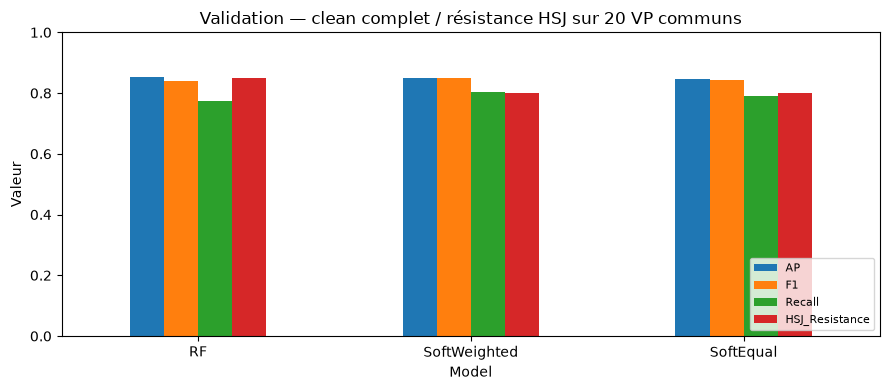

In [34]:
fig,ax=plt.subplots(figsize=(9,4))
ranking.set_index('Model')[CRITERIA].plot.bar(ax=ax,ylim=(0,1),rot=0)
ax.set_title('Validation — clean complet / résistance HSJ sur 20 VP communs')
ax.set_ylabel('Valeur'); ax.legend(loc='lower right',fontsize=8)
fig.tight_layout();fig.savefig(OUT/'24_validation_comparison.png',dpi=180);plt.show()


## 25 — Gel de la sélection avant toute ouverture du Test

Le fichier de décision est immuable dans cette expérience. Une relance vérifie qu'elle aboutit exactement à la même sélection. Le notebook exporte une recette JSON avec ordre des composants, poids, seuil et empreintes. On n'utilise pas un pickle de classe définie dans le notebook, fragile à charger dans FastAPI : la reconstruction future utilise cette recette et les trois modèles identifiés.


In [35]:
freeze_file=OUT/'25_frozen_decision.json'
if freeze_file.exists():
    assert json.loads(freeze_file.read_text(encoding='utf-8'))==DECISION, (
        'Décision différente après gel : ne pas écraser. Examiner la reproductibilité.')
else: json_write(freeze_file,DECISION)
RECIPE=dict(selected=SELECTED,component_order=list(MODELS),
    weights=(BEST_WEIGHTS.tolist() if SELECTED=='SoftWeighted' else [1/3]*3) if SELECTED!='RF' else None,
    voting='soft' if SELECTED!='RF' else 'native',threshold=THRESHOLD if SELECTED!='RF' else None,
    feature_order=FEATURES,model_paths={k:str(v) for k,v in MODEL_PATHS.items()},
    model_sha256=MODEL_HASHES,protocol_id=PROTOCOL_ID)
json_write(OUT/'25_selected_recipe.json',RECIPE)
selected_model=CANDIDATES[SELECTED]
print('Sélection gelée :',SELECTED)


Sélection gelée : RF


## 26 — Test clean après gel

Les données Test sont maintenant chargées et leur empreinte est enregistrée. Seul le modèle sélectionné est évalué ici. Le résultat peut être décevant sans entraîner un retour à la sélection : aucun poids ni seuil n'est modifié. Comme le Test a été vu dans les études précédentes, on parle de bilan exploratoire, pas d'une nouvelle validation indépendante.


In [36]:
assert json.loads(freeze_file.read_text(encoding='utf-8'))==DECISION
X_test,y_test=load_split('test')
assert list(X_test.columns)==FEATURES
TEST_HASHES={xy:sha256(DATA/f'{xy}_test.parquet') for xy in ['X','y']}
test_manifest=OUT/'26_test_hashes.json'
if test_manifest.exists():
    assert json.loads(test_manifest.read_text(encoding='utf-8'))==TEST_HASHES
else: json_write(test_manifest,TEST_HASHES)
test_clean=pd.DataFrame([metrics(SELECTED,selected_model,X_test,y_test)])
display(test_clean)
export_csv(test_clean,'26_selected_test_clean.csv')


,Model,AP,Precision,Recall,F1,MCC,ROC_AUC,Accuracy,TN,FP,FN,TP
0,RF,0.818871,0.888889,0.788732,0.835821,0.837061,0.968493,0.999483,42481,7,15,56


WindowsPath('C:/Users/MSI/Desktop/fraud_detection_memoire/artifacts/notebook13_hybrid/26_selected_test_clean.csv')

## 27 — Panel Test historique de 53 fraudes

Le panel est celui sauvegardé dans le projet, pas un nouvel échantillon construit après inspection des résultats. On vérifie ses positions et étiquettes. Si l'hybride manque déjà certaines fraudes, ce sont des faux négatifs clean, pas des attaques à lancer : la rétention clean est affichée et les attaques portent seulement sur les fraudes encore détectées. Les dénominateurs restent explicites. Le panel étant sélectionné historiquement sur des vrais positifs de modèles précédents, il ne représente pas toutes les fraudes.


In [37]:
test_panel_file=unique_file('common_test_fraud_positions.npy')
TEST_PANEL=np.asarray(np.load(test_panel_file),dtype=int)
assert TEST_PANEL.ndim==1 and len(TEST_PANEL)==53 and len(np.unique(TEST_PANEL))==53
assert TEST_PANEL.min()>=0 and TEST_PANEL.max()<len(X_test)
assert (y_test.iloc[TEST_PANEL].to_numpy()==1).all()
panel_predictions=np.asarray(selected_model.predict(X_test.iloc[TEST_PANEL]),dtype=int)
TEST_ELIGIBLE=TEST_PANEL[panel_predictions==1]
TEST_CLEAN_MISSES=int(np.sum(panel_predictions==0))
print(dict(Historical_Panel=53,Clean_Detected=len(TEST_ELIGIBLE),Clean_Misses=TEST_CLEAN_MISSES,
           Clean_Retention=len(TEST_ELIGIBLE)/53))
json_write(OUT/'27_test_panel.json',dict(positions=TEST_PANEL.tolist(),
    eligible_positions=TEST_ELIGIBLE.tolist(),clean_misses=TEST_CLEAN_MISSES))


{'Historical_Panel': 53, 'Clean_Detected': 53, 'Clean_Misses': 0, 'Clean_Retention': 1.0}


## 28 — HSJ Test conditionnelle à la sélection

Si l'hybride est retenu, il est attaqué directement avec le même protocole, sans transfert d'attaques des composants. Si RF est retenu, on réutilise les détails HSJ Test finaux NB11 afin d'éviter une nouvelle campagne.

La réutilisation exige les positions, le modèle, les flags `Eligible`/`Seed_Found`, les distances, les variables immuables et les exemples adversariaux exportés quand ils sont disponibles. On recalcule les flags de succès local à partir des détails, sans se fier à un ASR déjà arrondi. Si les détails sont incomplets ou ambigus, la robustesse est laissée non vérifiée ; le notebook ne relance pas RF automatiquement. Le résultat historique RF appartient au protocole NB11 et n'est pas mélangé à une comparaison Test de candidats NB13.


In [38]:
test_attack_df=None
RF_REUSE_NOTE=None
if SELECTED!='RF':
    if len(TEST_ELIGIBLE):
        test_attack_df=run_panel('test',X_test,TEST_ELIGIBLE,{SELECTED:selected_model})
    else:
        print('Aucune fraude du panel détectée : aucune attaque éligible.')
else:
    history_path=unique_file('selected_models_hsj_test.csv',optional=True)
    if history_path is None:
        RF_REUSE_NOTE='Détails NB11 absents : ASR non vérifiée ; aucune relance.'
    else:
        history=pd.read_csv(history_path)
        required={'Model','Source_Position','Eligible','Seed_Found','Adv_Pred',
                  'Linf','L2','Max_Immutable_Change','Local_Success'}
        if not required.issubset(history.columns):
            RF_REUSE_NOTE='Champs manquants dans les détails NB11 : '+str(sorted(required-set(history.columns)))
        else:
            r=history.loc[history.Model.eq('Random Forest')].copy()
            assert not r.Source_Position.duplicated().any(), 'Doublons RF dans les détails NB11.'
            assert set(r.Source_Position.astype(int))==set(TEST_PANEL.tolist()), 'Panel historique différent.'
            r=r.set_index('Source_Position').loc[TEST_PANEL].reset_index()
            def bool_column(s):
                mapped=s.astype(str).str.lower().map({'true':True,'false':False,'1':True,'0':False,
                                                     '1.0':True,'0.0':False})
                assert mapped.notna().all(), 'Flag historique absent ou ambigu.'
                return mapped.astype(bool)
            eligible=bool_column(r.Eligible); seeds=bool_column(r.Seed_Found)
            assert np.array_equal(eligible.to_numpy(),panel_predictions==1), 'Rétention clean différente de NB11.'
            known=eligible & seeds & r[['Adv_Pred','Linf','Max_Immutable_Change']].notna().all(axis=1)
            local=(r.Adv_Pred.eq(0) & r.Linf.le(EPS+1e-8) & r.Max_Immutable_Change.le(IMMUTABLE_TOL))
            if not np.array_equal(bool_column(r.Local_Success)[known].to_numpy(),local[known].to_numpy()):
                raise AssertionError('Flags de succès NB11 incompatibles avec les distances.')
            test_attack_df=pd.DataFrame(dict(Model='RF',Position=r.Source_Position.astype(int),
                Status=np.where(known,'ok',np.where(~eligible,'clean_miss','unverified_history')),
                Local_Success=[bool(v) if k else None for v,k in zip(local,known)],
                Seed_Queries=0,HSJ_Queries=0,Time_s=0.0,Linf=r.Linf,
                L2=r.L2,Immutable_Change=r.Max_Immutable_Change))
            test_attack_df=test_attack_df.loc[eligible.to_numpy()].copy()
            RF_REUSE_NOTE=('NB11 réutilisé ; provenance par fichier et panel, distances vérifiées. '
                           'Identité des anciens modèles/données non certifiée par empreintes historiques. '
                           'Requêtes et temps non récupérés : zéros techniques à ne pas interpréter comme coût nul.')
            json_write(OUT/'28_rf_history_provenance.json',dict(path=str(history_path),
                sha256=sha256(history_path),note=RF_REUSE_NOTE))
    print(RF_REUSE_NOTE)
if test_attack_df is not None: export_csv(test_attack_df,'28_selected_test_hsj_details.csv')


NB11 réutilisé ; provenance par fichier et panel, distances vérifiées. Identité des anciens modèles/données non certifiée par empreintes historiques. Requêtes et temps non récupérés : zéros techniques à ne pas interpréter comme coût nul.


## 29 — Bilan de résistance Test et dénominateurs

L'ASR d'évasion est calculée parmi les fraudes détectées avant attaque, avec couverture. Un second indicateur sur le panel historique inclut les faux négatifs clean : nombre de fraudes encore détectées après cette campagne divisé par 53. Les cas non évalués produisent des bornes, jamais une résistance parfaite par défaut.

Pour RF, la provenance historique reste une limite : faute d'empreintes anciennes, vérifier les distances et le panel ne démontre pas à lui seul que chaque modèle et split est strictement identique à celui utilisé dans NB11. Aucun nombre historique n'est inventé lorsque les fichiers ne suffisent pas.


In [39]:
TEST_REPORT=dict(selected=SELECTED,historical_panel_n=53,clean_misses=TEST_CLEAN_MISSES,
    eligible_n=int(len(TEST_ELIGIBLE)),test_hashes=TEST_HASHES,
    protocol_source='NB11_historical_details' if SELECTED=='RF' else 'NB13_direct_attack',
    history_note=RF_REUSE_NOTE,complete=False,ASR=None,HSJ_Resistance=None)
if not len(TEST_ELIGIBLE):
    TEST_REPORT.update(complete=True,ASR=None,HSJ_Resistance=None,Panel_Detection_After_Attack=0.0)
elif test_attack_df is not None:
    test_summary=attack_summary(test_attack_df,[SELECTED],len(TEST_ELIGIBLE))
    display(test_summary)
    export_csv(test_summary,'29_test_hsj_summary.csv')
    r=test_summary.iloc[0]
    n=int(r.Evaluated); k=int(r.Local_Success); unknown=len(TEST_ELIGIBLE)-n
    TEST_REPORT.update(evaluated=n,unknown=int(unknown),local_successes=k,complete=bool(r.Complete),
        ASR=float(r.ASR_Evaluated) if bool(r.Complete) else None,
        HSJ_Resistance=float(r.HSJ_Resistance) if bool(r.Complete) else None,
        Panel_Detection_Lower=float((len(TEST_ELIGIBLE)-k-unknown)/53),
        Panel_Detection_Upper=float((len(TEST_ELIGIBLE)-k)/53))
    if bool(r.Complete):
        TEST_REPORT['Panel_Detection_After_Attack']=float((len(TEST_ELIGIBLE)-k)/53)
json_write(OUT/'29_test_report.json',TEST_REPORT)
print(json.dumps(TEST_REPORT,indent=2,ensure_ascii=False))


,Model,Panel_N,Evaluated,Unknown,Coverage,Local_Success,ASR_Evaluated,ASR_Wilson_Low,ASR_Wilson_High,Panel_ASR_Lower,Panel_ASR_Upper,Complete,HSJ_Resistance,Seed_Missing,Mean_Linf_Success,Total_Queries,Total_Time_s
0,RF,53,53,0,1.0,3,0.056604,0.019437,0.153702,0.056604,0.056604,True,0.943396,0,0.028156,0,0.0


{
  "selected": "RF",
  "historical_panel_n": 53,
  "clean_misses": 0,
  "eligible_n": 53,
  "test_hashes": {
    "X": "91baa83527cadc64af999092910a5d006ebac9ea4bc04d943f6e515b34b5e026",
    "y": "0fe8692bef3c7cdbee1a36d85a5407806aa085f0efa795670c228cdf18b84c62"
  },
  "protocol_source": "NB11_historical_details",
  "history_note": "NB11 réutilisé ; provenance par fichier et panel, distances vérifiées. Identité des anciens modèles/données non certifiée par empreintes historiques. Requêtes et temps non récupérés : zéros techniques à ne pas interpréter comme coût nul.",
  "complete": true,
  "ASR": 0.05660377358490566,
  "HSJ_Resistance": 0.9433962264150944,
  "evaluated": 53,
  "unknown": 0,
  "local_successes": 3,
  "Panel_Detection_Lower": 0.9433962264150944,
  "Panel_Detection_Upper": 0.9433962264150944,
  "Panel_Detection_After_Attack": 0.9433962264150944
}


## 30 — Synthèse, exports et formulation pour le mémoire

Cette dernière cellule produit une synthèse calculée, une recette de reconstruction et un inventaire des sorties. Elle ne proclame jamais une robustesse certifiée ni une amélioration indépendante. Si le Test adversarial est incomplet, la conclusion l'annonce.

Pour utiliser le résultat dans l'application, reconstruire RF natif ou `FrozenHybrid` à partir des mêmes composants, de l'ordre des colonnes et de la recette exportée. Ne pas appliquer un nouveau scaler ni modifier le seuil. La mise en production, le chargement sécurisé et les contraintes métier doivent être traités dans le backend ; NB13 est une expérience de recherche.


In [40]:
assert all(sha256(MODEL_PATHS[k])==MODEL_HASHES[k] for k in MODELS), 'Modèle modifié pendant la campagne.'
assert json.loads(freeze_file.read_text(encoding='utf-8'))==DECISION
summary=dict(decision=DECISION,recipe=RECIPE,test_clean=test_clean.iloc[0].to_dict(),
             test_adversarial=TEST_REPORT,versions=VERSIONS,
             limitations=['Validation réutilisée pour sélectionner les poids.',
                          'Test déjà consulté dans NB11/NB12 ; extension exploratoire.',
                          'Panel HSJ sélectionné et petit ; résistance empirique, non certifiée.',
                          'Linf vérifié après génération, pas une optimisation garantie sous epsilon.',
                          'Pas de nouvelle évaluation ZOO de cet ensemble.'])
json_write(OUT/'30_final_summary.json',summary)
conclusion=(f'# Notebook 13 — synthèse exploratoire\n\n'
    f'Modèle retenu : **{SELECTED}**, par la règle Validation préétablie. '
    f'Gain relatif du meilleur hybride par rapport à RF : {relative_gain:.2%}.\n\n'
    f'AP Test du candidat figé : {float(test_clean.iloc[0].AP):.6f}. '
    f'Recall : {float(test_clean.iloc[0].Recall):.6f}.\n\n'
    + (f'ASR locale Test : {TEST_REPORT["ASR"]:.2%}.\n\n' if TEST_REPORT.get('ASR') is not None
       else 'ASR Test non établie ou non applicable ; consulter le rapport de couverture.\n\n')
    + 'Ces résultats décrivent une extension exploratoire sur des données déjà consultées. '
      'Ils ne constituent ni une confirmation indépendante, ni une certification de robustesse.\n')
(OUT/'30_conclusion.md').write_text(conclusion,encoding='utf-8')
print(conclusion)
print('Exports disponibles :')
for p in sorted(OUT.glob('*')):
    if p.is_file(): print(' -',p.name)


# Notebook 13 — synthèse exploratoire

Modèle retenu : **RF**, par la règle Validation préétablie. Gain relatif du meilleur hybride par rapport à RF : -0.48%.

AP Test du candidat figé : 0.818871. Recall : 0.788732.

ASR locale Test : 5.66%.

Ces résultats décrivent une extension exploratoire sur des données déjà consultées. Ils ne constituent ni une confirmation indépendante, ni une certification de robustesse.

Exports disponibles :
 - 06_components_validation.csv
 - 07_calibration_diagnostic.csv
 - 08_calibration.png
 - 09_diversity.csv
 - 11_equal_votes_validation.csv
 - 12_weight_grid_validation.csv
 - 13_weight_sensitivity.png
 - 14_candidates_validation.csv
 - 15_protocol.json
 - 15_protocol_backup.json
 - 19_hsj_validation_summary.csv
 - 20_rf_benchmark_validation.csv
 - 21_ranking_validation.csv
 - 21_score_sensitivity.csv
 - 22_bootstrap_descriptive.csv
 - 24_validation_comparison.png
 - 25_frozen_decision.json
 - 25_selected_recipe.json
 - 26_selected_test_clean.csv
 - 26_te

## Questions à expliquer au jury

**Pourquoi ces trois modèles ?** Ils sont déjà entraînés et défendus dans NB11 et offrent deux familles de construction d'arbres : bagging (RF) et boosting (XGB/LGBM). Leur combinaison est une hypothèse à tester ; la diversité doit être mesurée, pas supposée.

**Pourquoi pas un stacking ?** Un méta-modèle exigerait des prédictions hors pli ou un ensemble séparé et une nouvelle étape d'apprentissage. L'objectif est ici d'agréger les modèles figés avec une complexité limitée.

**Pourquoi attaquer l'ensemble directement ?** La frontière du vote soft diffère de celles de ses composants. La résistance de chaque composant ne prouve pas celle de l'agrégation.

**Pourquoi pas calibrer maintenant ?** La Validation sert déjà à sélectionner les poids. Une calibration apprise et évaluée sur les mêmes observations donnerait une comparaison optimiste. Sans nouveau split indépendant, NB13 se limite au diagnostic.

**Pourquoi RF peut-il rester final ?** L'hybridation ajoute des modèles, de la latence et de la maintenance. La règle de parcimonie protège contre une complexification sans gain suffisant ; elle n'a pas pour but de forcer RF à gagner.

**Que veut dire une attaque HSJ sans succès ?** Cette exécution n'a trouvé aucune évasion satisfaisant les contraintes. D'autres initialisations, budgets ou attaques peuvent réussir. Une seed absente est un cas non évalué.

**Peut-on écrire « solution hybride validée définitivement » ?** Non. Les poids sont sélectionnés sur une Validation réutilisée et le Test était déjà connu. La formulation correcte est « étude exploratoire d'une agrégation de modèles défendus, avec évaluation directe de résistance empirique à HSJ ».

## Dépannage

- **Chemin introuvable** : renseigner `PROJECT_ROOT_OVERRIDE` à la cellule 1 ; ne pas déplacer les exports au hasard.
- **Plusieurs copies** : renseigner `PATH_OVERRIDES` avec le chemin du fichier choisi après vérification de sa provenance.
- **Version ou ordre des colonnes différent** : arrêter ; ne pas supprimer les assertions pour continuer.
- **Seed absente / erreur** : examiner le JSON du couple concerné. Après correction d'un problème technique sans changement de protocole, retirer uniquement le JSON de ce couple pour le recalculer. Un changement de modèle, de données ou de paramètres exige un nouveau `OUT` et une nouvelle expérience explicitement nommée.
- **Échec d'éligibilité sur le panel Validation** : ne pas filtrer les observations ou ajuster les poids à l'aveugle. La comparaison historique doit être redéfinie explicitement dans une nouvelle expérience ; les métriques clean restent disponibles.
- **RF historique non vérifiable** : laisser la robustesse Test non établie et analyser les exports NB11. Ne jamais insérer manuellement 3/53 dans les résultats calculés.
- **Calcul interrompu** : rouvrir NB13, exécuter de haut en bas ; les JSON terminés sont repris. Le protocole doit rester identique.

## Ce qui est vérifié à la livraison

La structure JSON du notebook, la syntaxe Python des cellules et les fonctions d'agrégation, de métriques et de décision ont été contrôlées avec des données synthétiques. Les modèles, les splits parquet et ART de ton environnement local ne sont pas joints : la campagne réelle n'a donc pas été exécutée ici et aucun résultat NB13 n'est prérempli.
